## Torch Basics

В ячейках ниже вам предложено выполнить базовые операции с тензорами, модулями и параметрами, чтобы разобраться, чем является каждая сущность и какие операции можно делать с ними

In [8]:
# ⚠️ Важно!
# Из ячейки не нужно убирать или добавлять другие импорты или объединять с тдругими ячейками
# Нельзя менять интерфейс (входные аргументы)
# Это может сломать автотесты

import torch
import torch.nn as nn

class MyLinear(nn.Module):
    """Реализация линейного слоя (аналог nn.Linear).

    Линейный слой выполняет преобразование: output = input @ weight.T + bias

    Args:
        in_features: размерность входного вектора
        out_features: размерность выходного вектора
        bias: использовать ли bias (по умолчанию True)
    """
    def __init__(self, in_features: int, out_features: int, bias: bool = True):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features

        # TODO: инициализировать параметр weight размером [out_features, in_features]
        # Используйте nn.Parameter для создания обучаемого параметра
        # self.weight = nn.Parameter(...)

        # class torch.nn.parameter.Parameter(data=None, requires_grad=True)[source]

        # torch.randn(*size, *, generator=None, out=None, dtype=None, 
        # layout=torch.strided, device=None, requires_grad=False, pin_memory=False)
        
        # инициализируем СЛУЧАЙНЫМ образом вектор весов
        
        self.weight = nn.Parameter(data=torch.randn(size=(out_features, in_features)), requires_grad=True)

        # TODO: инициализировать параметр bias размером [out_features] (если bias=True)
        # self.bias = nn.Parameter(...) if bias else None
        if bias:
            # size=out_features,
            self.bias = nn.Parameter(torch.randn(out_features))
        else:
            self.bias = None

        # Подсказка: можно использовать torch.randn для инициализации

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Выполняет линейное преобразование.

        Args:
            x: входной тензор формы [batch_size, in_features]

        Returns:
            output: выходной тензор формы [batch_size, out_features]
        """
        # TODO: реализовать forward pass
        # Подсказка: используйте torch.matmul или оператор @ для матричного умножения

        
        # Forward pass

        output = x @ self.weight.T
    
        if self.bias is not None:
            output = output + self.bias

        return output
        
        # raise NotImplementedError


def task_linear_mse_loss(
    layer: MyLinear,
    x: torch.Tensor,
    y: torch.Tensor
) -> tuple[torch.Tensor, torch.Tensor]:
    """Вычислить MSE loss и градиенты по параметрам MyLinear.

    Требования:
    - layer должен быть экземпляром MyLinear
    - x - входной тензор формы [batch_size, in_features]
    - y - целевой тензор формы [batch_size, out_features]
    - Выполните forward pass через layer
    - Вычислите MSE loss: loss = mean((output - y)^2)
    - Вызовите backward() на loss
    - Верните кортеж (loss, weight_grad), где weight_grad - градиент по weight

    Returns:
        loss: torch.Tensor - скалярное значение MSE loss
        weight_grad: torch.Tensor - градиент по параметру weight формы [out_features, in_features]
    """
    # task description: MSE loss и градиенты для MyLinear
    # ...
    # forward pass
    output = layer(x)

    # MSE loss: mean((output - y)^2)
    loss = ((output - y) ** 2).mean()

    # backward
    loss.backward()

    # gradient по weight
    weight_grad = layer.weight.grad

    return loss, weight_grad

def task_grad_sum_of_squares(x: torch.Tensor) -> torch.Tensor:
    """Градиенты можно считать и по обычным тензорам, не только по параметрам.
    Посчитайте градиент функции f(x) = sum(x^2) по x.

    Требования:
    - x должен быть torch.Tensor с requires_grad=True
    - посчитайте f(x), вызовите backward(), верните x.grad

    Returns:
        grad: torch.Tensor той же формы, что и x
    """
    # task description: градиент суммы квадратов
    # ...

    # f(x) = sum(x^2)
    f = (x ** 2).sum()

    # backward
    f.backward()

    # gradient по x
    return x.grad

In [10]:
def test_my_linear_basic():
    """Базовый тест для MyLinear: проверка формы выхода."""
    in_features = 5
    out_features = 3
    batch_size = 10

    layer = MyLinear(in_features, out_features)
    x = torch.randn(batch_size, in_features)

    # Проверка, что слой имеет правильные параметры
    assert hasattr(layer, 'weight'), "MyLinear должен иметь параметр weight"
    assert layer.weight.shape == (out_features, in_features), \
        f"weight должен иметь форму ({out_features}, {in_features}), получено {layer.weight.shape}"

    if layer.bias is not None:
        assert layer.bias.shape == (out_features,), \
            f"bias должен иметь форму ({out_features},), получено {layer.bias.shape}"

    # Проверка forward pass
    output = layer(x)
    assert output.shape == (batch_size, out_features), \
        f"Выход должен иметь форму ({batch_size}, {out_features}), получено {output.shape}"


def test_my_linear_no_bias():
    """Тест MyLinear без bias."""
    in_features = 4
    out_features = 2
    batch_size = 8

    layer = MyLinear(in_features, out_features, bias=False)
    x = torch.randn(batch_size, in_features)

    assert layer.bias is None, "При bias=False параметр bias должен быть None"

    output = layer(x)
    assert output.shape == (batch_size, out_features)


def test_my_linear_vs_torch_linear():
    """Сравнение MyLinear с nn.Linear (проверка правильности реализации)."""
    in_features = 7
    out_features = 4
    batch_size = 6

    # Создаем два слоя
    my_layer = MyLinear(in_features, out_features)
    torch_layer = nn.Linear(in_features, out_features)

    # Копируем веса из torch_layer в my_layer для сравнения
    my_layer.weight.data = torch_layer.weight.data.clone()
    if my_layer.bias is not None:
        my_layer.bias.data = torch_layer.bias.data.clone()

    x = torch.randn(batch_size, in_features)

    # Получаем выходы
    my_output = my_layer(x)
    torch_output = torch_layer(x)

    # Проверяем, что выходы совпадают (с небольшой погрешностью)
    assert torch.allclose(my_output, torch_output, atol=1e-5), \
        "Выход MyLinear должен совпадать с выходом nn.Linear при одинаковых весах"


def test_my_linear_gradients():
    """Проверка работы градиентов в MyLinear."""
    in_features = 3
    out_features = 2
    batch_size = 5

    layer = MyLinear(in_features, out_features)
    x = torch.randn(batch_size, in_features, requires_grad=True)

    output = layer(x)
    loss = output.sum()
    loss.backward()

    # Проверяем, что градиенты вычислены
    assert x.grad is not None, "Градиент по входу должен быть вычислен"
    assert layer.weight.grad is not None, "Градиент по weight должен быть вычислен"
    if layer.bias is not None:
        assert layer.bias.grad is not None, "Градиент по bias должен быть вычислен"


def test_task_linear_mse_loss():
    """Тест для task_linear_mse_loss."""
    in_features = 4
    out_features = 2
    batch_size = 5

    # Создаем слой и данные
    layer = MyLinear(in_features, out_features)
    x = torch.randn(batch_size, in_features)
    y = torch.randn(batch_size, out_features)

    # Вызываем функцию
    loss, weight_grad = task_linear_mse_loss(layer, x, y)

    # Проверки
    assert isinstance(loss, torch.Tensor), "loss должен быть torch.Tensor"
    assert loss.dim() == 0, "loss должен быть скаляром"

    assert isinstance(weight_grad, torch.Tensor), "weight_grad должен быть torch.Tensor"
    assert weight_grad.shape == (out_features, in_features), \
        f"weight_grad должен иметь форму ({out_features}, {in_features}), получено {weight_grad.shape}"

    # Проверяем, что градиент не None
    assert weight_grad is not None, "weight_grad не должен быть None"

    # Проверяем правильность вычисления loss вручную
    output = layer(x)
    expected_loss = ((output - y) ** 2).mean()
    assert torch.allclose(loss, expected_loss.detach(), atol=1e-5), \
        f"loss должен быть равен MSE: ожидалось {expected_loss.item()}, получено {loss.item()}"


def test_task_grad_sum_of_squares():
    x = torch.randn(4, 3, requires_grad=True)
    grad = task_grad_sum_of_squares(x)

    assert isinstance(grad, torch.Tensor), "Ожидается torch.Tensor"
    assert grad.shape == x.shape

    # d/dx sum(x^2) = 2x
    assert torch.allclose(grad, 2 * x.detach()), "Градиент должен быть равен 2*x"


test_task_grad_sum_of_squares()
print("OK: task_grad_sum_of_squares")

test_my_linear_basic()
print("OK: test_my_linear_basic")

test_my_linear_no_bias()
print("OK: test_my_linear_no_bias")

test_my_linear_vs_torch_linear()
print("OK: test_my_linear_vs_torch_linear")

test_my_linear_gradients()
print("OK: test_my_linear_gradients")

test_task_linear_mse_loss()
print("OK: task_linear_mse_loss")

OK: task_grad_sum_of_squares
OK: test_my_linear_basic
OK: test_my_linear_no_bias
OK: test_my_linear_vs_torch_linear
OK: test_my_linear_gradients
OK: task_linear_mse_loss


## MLP

Теперь, когда мы осовились с базовыми операциями в торче, можно реализовать свой класс для MLP и по желанию обучить его.

Наш класс MLP должен быть гибко конфигурируемым: он принимает аргументом все скрытые размерности и функцию активации.

In [12]:
# ⚠️ Важно!
# Из ячейки не нужно убирать или добавлять другие импорты или объединять с тдругими ячейками
# Нельзя менять интерфейс (входные аргументы)
# Это может сломать автотесты

import torch
import torch.nn as nn
import torch.nn.functional as F


# initialize a model
class MyMLP(nn.Module):
    def __init__(
        self,
        hidden_dims: list[int],
        input_dim: int=2,
        output_dim: int=1,
        activation_cls=nn.ReLU,
    ):
        super().__init__()

        self.input_dim = input_dim
        self.output_dim = output_dim
        self.hidden_dims = hidden_dims

        # self.input_layer = ...
        # self.hidden_layers = ... # use nn.ModuleList https://pytorch.org/docs/stable/generated/torch.nn.ModuleList.html
        # self.output_layer = ...
        # input layer
        self.input_layer = nn.Linear(input_dim, hidden_dims[0])
        
        # hidden layers
        self.hidden_layers = nn.ModuleList(
            [
                nn.Linear(hidden_dims[i], hidden_dims[i + 1])
                for i in range(len(hidden_dims) - 1)
            ]
        )

        # output layer
        self.output_layer = nn.Linear(hidden_dims[-1], output_dim)

        # activation function
        self.activation = activation_cls()

    def forward(self, x_coordinates):
        # x_coordinates ~ [batch_size, input_dim]

        latents = self.activation(self.input_layer(x_coordinates))

        # TODO compute hidden layers latents
        # Checkout nn.ModuleList doc to understand how to iterate over it https://pytorch.org/docs/stable/generated/torch.nn.ModuleList.html

        # hidden layers
        for layer in self.hidden_layers:
            latents = self.activation(layer(latents))
            
        # raise NotImplementedError

        scores = self.output_layer(latents)  # [batch_size, output_dim]
        return scores


In [14]:
# Если вы все сделали правильно, должны пройти тесты

def count_learnable_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def test_count_parameters():
    model_1_hidden_layer = MyMLP(hidden_dims=[100, 100])
    assert count_learnable_parameters(model_1_hidden_layer) == 10501
    assert model_1_hidden_layer.forward(torch.rand(10, 2)).shape == torch.Size([10, 1])

    model_2_hidden_layer = MyMLP(hidden_dims=[100, 100, 100])
    assert count_learnable_parameters(model_2_hidden_layer) == 20601

    model_3_hidden_layer = MyMLP(hidden_dims=[100, 100, 100, 100])
    assert count_learnable_parameters(model_3_hidden_layer) == 30701


test_count_parameters()
print("OK")

OK


In [16]:
# Если вы все сделали правильно, должны пройти тесты

def _assert_linear_shapes(layer: nn.Linear, in_dim: int, out_dim: int):
    assert isinstance(layer, nn.Linear), f"Expected nn.Linear, got {type(layer)}"
    assert layer.in_features == in_dim, f"in_features: expected {in_dim}, got {layer.in_features}"
    assert layer.out_features == out_dim, f"out_features: expected {out_dim}, got {layer.out_features}"


def test_hidden_layers_order_and_shapes():
    input_dim = 2
    output_dim = 3

    # Case 1: single hidden layer => hidden_layers must be empty
    hidden_dims = [5]
    model = MyMLP(input_dim=input_dim, output_dim=output_dim, hidden_dims=hidden_dims, activation_cls=nn.ReLU)

    _assert_linear_shapes(model.input_layer, input_dim, hidden_dims[0])
    assert isinstance(model.hidden_layers, nn.ModuleList), "hidden_layers must be nn.ModuleList"
    assert len(model.hidden_layers) == 0, f"Expected 0 hidden layers, got {len(model.hidden_layers)}"
    _assert_linear_shapes(model.output_layer, hidden_dims[-1], output_dim)

    # Case 2: multiple hidden layers => ModuleList must connect hidden_dims sequentially
    hidden_dims = [4, 7, 11]
    model = MyMLP(input_dim=input_dim, output_dim=output_dim, hidden_dims=hidden_dims, activation_cls=nn.ReLU)

    _assert_linear_shapes(model.input_layer, input_dim, hidden_dims[0])

    assert isinstance(model.hidden_layers, nn.ModuleList), "hidden_layers must be nn.ModuleList"
    assert len(model.hidden_layers) == len(hidden_dims) - 1, (
        f"Expected {len(hidden_dims) - 1} hidden layers, got {len(model.hidden_layers)}"
    )

    expected_pairs = list(zip(hidden_dims[:-1], hidden_dims[1:]))  # (in_dim, out_dim) per hidden layer
    for i, (layer, (in_dim, out_dim)) in enumerate(zip(model.hidden_layers, expected_pairs)):
        assert isinstance(layer, nn.Linear), f"hidden_layers[{i}] must be nn.Linear, got {type(layer)}"
        _assert_linear_shapes(layer, in_dim, out_dim)

    _assert_linear_shapes(model.output_layer, hidden_dims[-1], output_dim)


# run
test_hidden_layers_order_and_shapes()
print("OK")


OK


In [18]:
from sklearn.datasets import make_moons, make_blobs

# loss function
def loss(model, Xbatch, ybatch):

    Xbatch = torch.tensor(Xbatch).float() # [ batch_size, 2 ]

    # ybatch.max() == 1, ybatch.min() == -1
    # важно: приводим к форме [ batch_size, 1 ], чтобы не было broadcasting в [batch, batch]
    ybatch = torch.tensor(ybatch).float().unsqueeze(-1) # [ batch_size, 1 ]

    # forward the model to get scores
    model_prediction = model.forward(Xbatch) # [ batch_size, 1 ]

    # svm "max-margin" loss
    losses = F.relu(1 - ybatch * model_prediction) # [ batch_size, 1 ]
    loss = losses.mean()

    # L2 regularization
    alpha = 1e-4
    reg_loss = alpha * sum((p*p).sum() for p in model.parameters())
    total_loss = loss + reg_loss

    # also get accuracy
    accuracy = ((ybatch > 0) == (model_prediction > 0)).float().mean()
    return total_loss, accuracy


# optimization

def train(model, learning_rate=0.1):

    Xbatch, ybatch = make_moons(n_samples=100, noise=0.1, random_state=1)
    ybatch = ybatch * 2 - 1 # make y be -1 or 1

    for k in range(300):

        model.zero_grad() # обнуляем градиенты с предыдущего шага

        # forward
        total_loss, acc = loss(model, Xbatch, ybatch)

        # backward
        total_loss.backward() # вычисляем новые значения градиентов

        # шаг оптимизации
        # update (sgd)
        for p in model.parameters():
            p.data = p.data - learning_rate * p.grad

        if k % 50 == 0:
            print(f"step {k} loss {total_loss.data}, accuracy {acc*100}%")


model = MyMLP(hidden_dims=[100, 100])

print("count_learnable_parameters", count_learnable_parameters(model))

train(model, learning_rate=0.1)

count_learnable_parameters 10501
step 0 loss 1.001560091972351, accuracy 50.0%
step 50 loss 0.23712675273418427, accuracy 88.0%
step 100 loss 0.16000960767269135, accuracy 96.0%
step 150 loss 0.07608546316623688, accuracy 97.0%
step 200 loss 0.0384557880461216, accuracy 99.0%
step 250 loss 0.030000783503055573, accuracy 100.0%


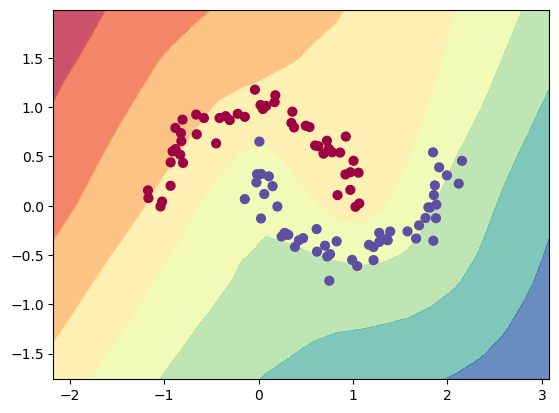

In [20]:
import numpy as np
import matplotlib.pyplot as plt

def visualize_model_prediction(model):

    X, y = make_moons(n_samples=100, noise=0.1, random_state=1)

    h = 0.25
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                        np.arange(y_min, y_max, h))
    Xmesh = np.c_[xx.ravel(), yy.ravel()]

    if isinstance(model, nn.Module):
        with torch.no_grad():
            Xbatch = torch.tensor(Xmesh).float()

            scores = model.forward(Xbatch)
            Z = scores.numpy()

    else:
        scores = model.decision_function(Xmesh)
        Z = scores

    Z = Z.reshape(xx.shape)

    fig = plt.figure()
    plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())

visualize_model_prediction(model)